In [2]:
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [3]:
data_folder = Path("../data/dart_boards")

def load_boards(folder: Path) -> dict[str, np.ndarray]:
    boards = {}

    for path in folder.iterdir():
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            image = cv2.imread(str(path))

            if image is not None:
                boards[path.stem] = image

    return boards

boards = load_boards(data_folder)

In [4]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt


data_folder = Path("../data/dart_boards")
boards = load_boards(data_folder)


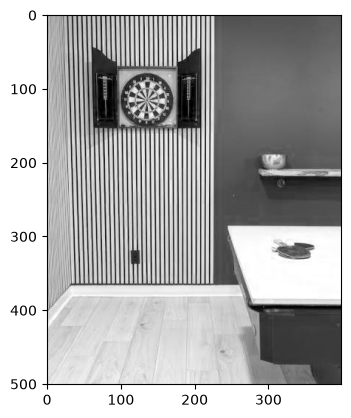

In [19]:
img = cv2.cvtColor(boards["board 1"],cv2.COLOR_BGR2RGB)
img_green = img[:,:,0]
plt.imshow(img_green, cmap="gray")

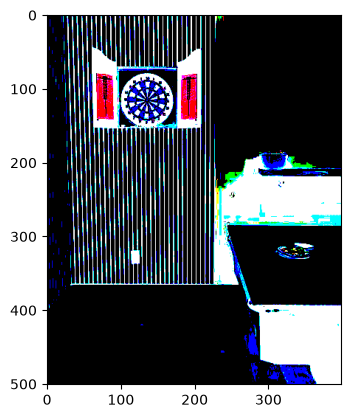

In [20]:
_, img_thresh = cv2.threshold(img, 80, 255, 1)

# Create erosion kernel
kernel = np.ones((3, 3), dtype=np.uint8)


# Erode
img_eroded = cv2.dilate(
    img_thresh,
    kernel,
    iterations=1
)

kernelPrewittx = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])
kernelPrewitty = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])

# Apply Prewitt X Kernel
img_prewittx = cv2.filter2D(img_eroded, -1, kernelPrewittx)

# Apply Prewitt Y Kernel
img_prewitty = cv2.filter2D(img_eroded, -1, kernelPrewitty)

# Combine the two images
img_prewitt = img_prewittx + img_prewitty

# Convert the image back to uint8
img_prewitt_uint8 = cv2.convertScaleAbs(img_prewitt)

plt.imshow(img_thresh, cmap="gray")

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
gray = img_thresh
# gray = cv2.GaussianBlur(gray, (9, 9), 2)

circles = cv2.HoughCircles(
    gray,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=30,
    param1=20,
    param2=30,
    minRadius=50,
    maxRadius=100
)
print(circles)
# Draw detected circles
result = img.copy()

if circles is not None:
    circles = np.round(circles[0]).astype(int)

    for x, y, r in circles:
        cv2.circle(result, (x, y), r, (255, 0, 0), 2)
        cv2.circle(result, (x, y), 2, (0, 255, 0), 3)

plt.figure(figsize=(10, 10))
plt.imshow(result)
plt.axis("off")
plt.show()

error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\hough.cpp:2284: error: (-215:Assertion failed) !_image.empty() && _image.type() == CV_8UC1 && (_image.isMat() || _image.isUMat()) in function 'cv::HoughCircles'
